In [1]:
#importing library
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import data_utils as du

In [2]:
#Importing the dataset
reg_path= "../../data/Regression_datasets/energy.csv"
reg_data= pd.read_csv(reg_path)
print(reg_data.head())

   temperature   humidity  appliances  energy_usage
0    35.733322  40.472388          15    174.469776
1    32.968205  75.408205           4    132.435368
2    37.227099  28.223387          18    182.695242
3    20.538683  55.947684          12    129.491119
4    14.851723  83.264081          16    138.003259


In [3]:
#data exploration
du.data_exploration(reg_data)

DATA EXPLORATION
Shape of dataset: 10000 rows, 4 columns

Columns: ['temperature', 'humidity', 'appliances', 'energy_usage']

Data Types:
 temperature     float64
humidity        float64
appliances        int64
energy_usage    float64
dtype: object

Missing Values:
 temperature     0
humidity        0
appliances      0
energy_usage    0
dtype: int64

Statistical Summary:
         temperature      humidity    appliances  energy_usage
count  10000.000000  10000.000000  10000.000000  10000.000000
mean      27.546432     54.955081      9.964700    132.385440
std       10.096148     20.167834      3.172895     29.299048
min       10.002778     20.007518      0.000000     32.461446
25%       18.836221     37.706143      8.000000    111.434941
50%       27.387380     54.855562     10.000000    132.427768
75%       36.302188     72.455772     12.000000    152.684633
max       44.998788     89.997501     24.000000    237.802733


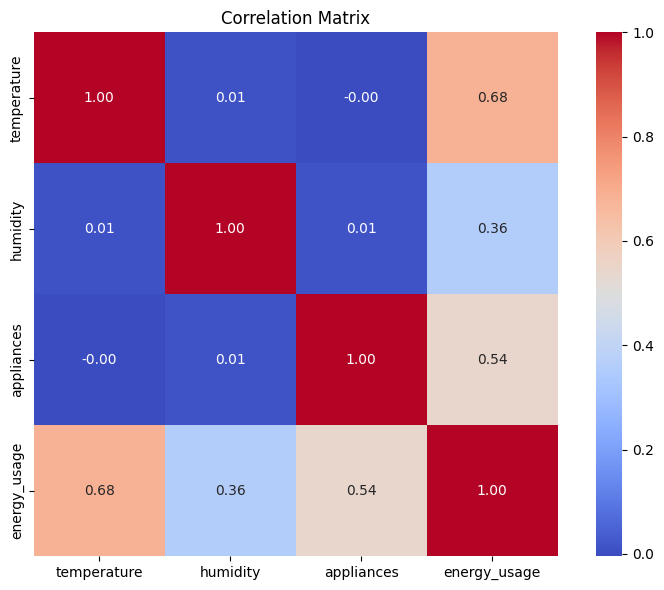

In [4]:
#data visualization
corr = du.get_correlation_matrix(reg_data)
du.plot_correlation_matrix(corr)

temperage and energy usage are 68 percent correlated. and applicances and energy usage  are 54 % co-related. humidity and energy usage 36% co-related.

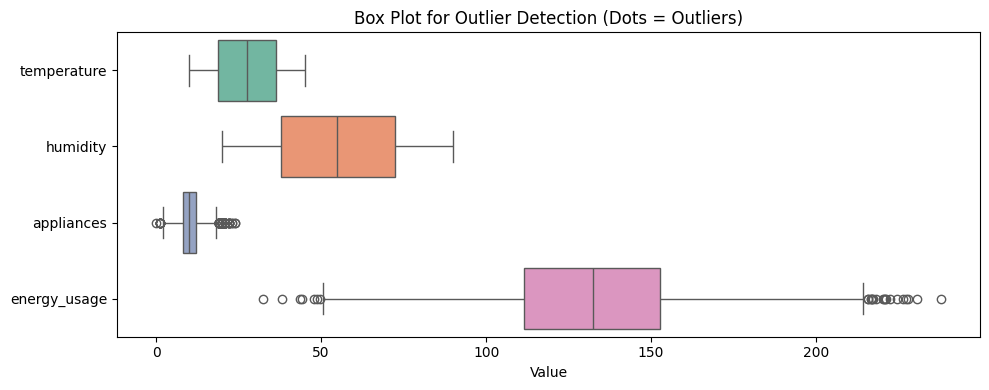

In [5]:
#check for outliers
cols = reg_data.columns
du.plot_boxplots(reg_data, cols)

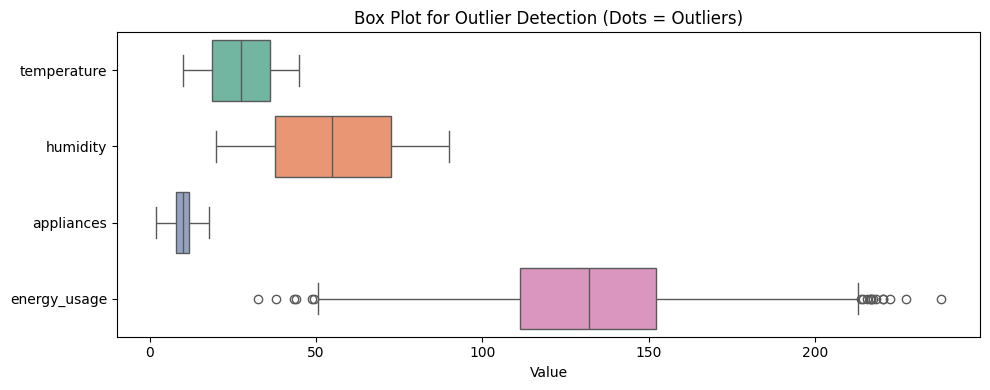

In [7]:
cols_outliers = ['appliances']

df_clean = du.remove_outliers_iqr(reg_data, cols_outliers)

du.plot_boxplots(df_clean, cols)


In [9]:
#linear regression 
X = df_clean.drop('energy_usage', axis=1)
y = df_clean['energy_usage']

In [10]:
model, mse, r2, y_test, y_pred =    du.linear_regression_model(X, y)

Mean Squared Error: 97.9582
R-squared: 0.8871


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [11]:
du.cross_validation(model, X, y, cv=5)

5-Fold Cross-Validation (r2): [0.87446068 0.88370209 0.88604695 0.88196432 0.88141852]
Average CV score: 0.8815 (± 0.0039)


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i

array([0.87446068, 0.88370209, 0.88604695, 0.88196432, 0.88141852])

88% prediction accuracy can able to attain using this data


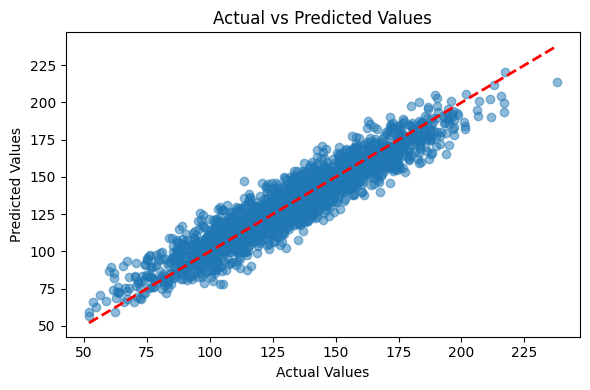

In [12]:
du.plot_actual_vs_predicted(y_test, y_pred)